# Jordan Lake Spatiotemporal Simulation
ASV wind characterization simulation at the Jordan Lake mission domain.

Features:
- STGPKF Formulation
    - Generate Synthetic Data
    - Make estimates based upon existing measurements
- Ergodic Control
- Real-Time SOC-Based speed control
- Known Hyperparameters

In [1]:
# Import Packages
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

using LinearAlgebra
using Random
using Statistics
using Plots
using LaTeXStrings
using Revise
using StaticArrays
using Interpolations
using LazySets
using SpatiotemporalGPs
using JLD2
using LinearInterpolations
using DifferentialEquations
using ForwardDiff
using LinearAlgebra, StatsBase

In [2]:
# Import modules
include("../../../src/jordan_lake_domain.jl")
# include("../../../src/stgpkf.jl")
include("../../../src/kf.jl")
include("../../../src/ngpkf.jl")
include("../../../src/SyntheticData.jl")
include("../../../src/ergodic.jl")
include("../../../src/variograms.jl")
include("../../../src/SOC_Controller.jl")
include("../../../src/simulator_spatial.jl")
include("../../../src/simulator_ST.jl")
include("../../../src/Convex_bound_avoidance.jl")
include("../../../src/transects.jl")

┌ Warning: Replacing docs for Main.Variograms.hp_fit :: Tuple{Any} in module
│ Main.Variograms
└ @ Base.Docs docs/Docs.jl:243


Main.Transects

# Synthetic Data

In [79]:
# Define simulation time-scale/steps
Δt = 2.5 # seconds
dt_min = Δt/(60) # convert ΔT from seconds to minutes
dt_hrs = Δt/(60*60) # convert ΔT from seconds to hours
T_begin = 9.0; # hours
T_end = 15.0; # hours 
ts_hrs = T_begin:dt_hrs:T_end # hours
ts_min = T_begin*60:dt_min:T_end*60

540.0:0.041666666666666664:900.0

In [80]:
# setup the spatial and temporal kernels
σt = 1.0   # m/s
σs = 1.0   # m/s
# lt = 0.50*60.0  # minutes
lt = 1000.0 * 60.0
ls = 0.25   # km

kt = Matern(1/2, σt, lt)
ks = Matern(1/2, σs, ls)

# Create spatial domain
# determine the spatial step size
dx = 0.05 # km

# create the spatial domain
xs = 0:dx:1.6
ys = 0:dx:1.9
grid_pts = vec([@SVector[x, y] for x in xs, y in ys]);


w_rated_val = 1.0

1.0

In [81]:
# generate synthetic data
synthetic_data = STGPKF.generate_spatiotemporal_process(xs, ys, dt_min, (T_end-T_begin)*60, ks, kt);

[ Info: Saved animation to /tmp/jl_AdeDKL2nWP.gif


Plots.AnimatedGif("/tmp/jl_AdeDKL2nWP.gif")
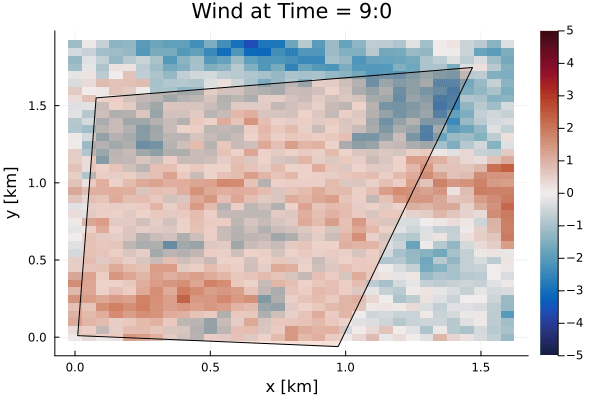

In [82]:
bounded_windfield = @animate for time_idx in 1:100:length(synthetic_data.ts)
    heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:, :, time_idx]', clims=(-5,5), cmap=:balance, plottype=:wx)
    polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])  # Close the polygon
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.2, label="")
    title!("Wind at Time = $(Int(floor(ts_hrs[time_idx]))):$(Int(floor(mod(ts_hrs[time_idx],1)*60)))")
    xlabel!("x [km]")
    ylabel!("y [km]")
    # plot!(aspect_ratio=:equal)
end
gif(bounded_windfield)

# Transect Sim

## Controller Setup

In [83]:
# Create STGPKF Problem
problem = STGPKFProblem(grid_pts, ks, kt, dt_min)
kern = ks
ngp_grid_x = synthetic_data.xs
ngp_grid_y = synthetic_data.ys
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

# ASV Start Location
x0s = [@SVector[0.75, 0.75] for i=1:1]

1-element Vector{SVector{2, Float64}}:
 [0.75, 0.75]

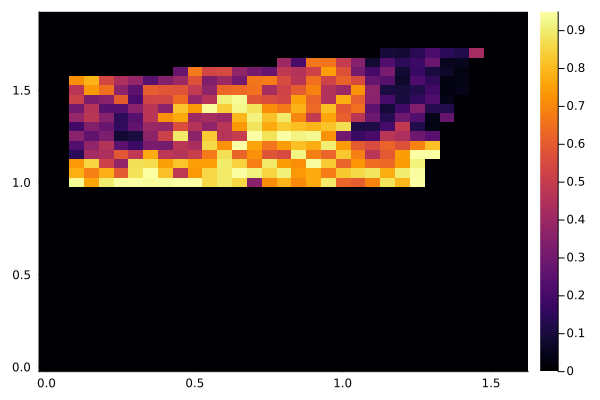

In [84]:
target_q = 0.95

# Set the rated value matrix    
Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
w_rated = ones(Nx, Ny)
w_rated *= w_rated_val

#   Compute the target matrix 
lambda_param = 0.25
delta = -lambda_param*((synthetic_data.data[:,:,1] - w_rated).^2)
q_target_temp = target_q*(exp.(delta)) 


# Mask the matrix such that q_target is zero outisde the domain
# x_domain = range(0, 1.4, length=Nx)
# y_domain = range(0, 6.5, length=Ny)
x_domain = synthetic_data.xs
y_domain = synthetic_data.ys

for i in 1:length(x_domain)
    for j in 1:length(y_domain)
        p = [x_domain[i], y_domain[j]]
        if (p ∈ JordanLakeDomain.convex_polygon.polygon) == false
            q_target_temp[i, j] = 0.0
        end
        if y_domain[j] < 1.0
            q_target_temp[i, j] = 0.0
        end
    end
end


heatmap(synthetic_data.xs, synthetic_data.ys, q_target_temp')

In [85]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(Δt)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [86]:
function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end

Clarity_delta_new (generic function with 1 method)

In [87]:

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val, convex_polygon;
    ergo_grid,
    ergo_q_map,
    traj,
    umax= 0.15, #30.0 * 60 / 1000,
    ΔT,
    kwargs...
    )
    
target_q = 0.95

# Set the rated value matrix    
Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
w_rated = ones(Nx, Ny)
w_rated *= w_rated_val

#   Compute the target matrix 
lambda_param = 0.25
delta = -lambda_param*((synthetic_data.data[:,:,1] - w_rated).^2)
q_target_temp = target_q*(exp.(delta)) 


# Mask the matrix such that q_target is zero outisde the domain
# x_domain = range(0, 1.4, length=Nx)
# y_domain = range(0, 6.5, length=Ny)
x_domain = synthetic_data.xs
y_domain = synthetic_data.ys

for i in 1:length(x_domain)
    for j in 1:length(y_domain)
        p = [x_domain[i], y_domain[j]]
        if (p ∈ convex_polygon.polygon) == false
            q_target_temp[i, j] = 0.0
        end
        if y_domain[j] < 1.0
            q_target_temp[i, j] = 0.0
        end
    end
end


# Get it in the right shape
q_target_itp = linear_interpolation((x_domain, y_domain), q_target_temp, extrapolation_bc=Interpolations.Line())
q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     


target_spatial_dist = zeros(size(ergo_q_map))
Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      

for i in CartesianIndices(target_spatial_dist)
    if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
        target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
    else
        target_spatial_dist[i] = 0.0
    end
end
    
u = [ErgodicController.controller_single_integrator_cvx_bound(ergo_grid, x, traj, target_spatial_dist, convex_polygon; umax=umax, do_boundary_correction=true) for x in xs]

#     println(u)

return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

## Generate SOC Target Profile

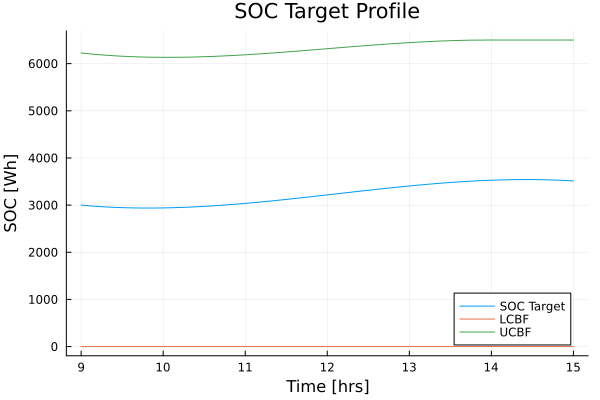

In [88]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts_hrs, dt_hrs);
ucbf = SoCController.compute_ucbf(ts_hrs, dt_hrs);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts_hrs, dt_hrs);
plot(ts_hrs, soc_target, label="SOC Target")
plot!(ts_hrs, lcbf, label="LCBF")
plot!(ts_hrs,ucbf, label="UCBF")
xlabel!("Time [hrs]")
ylabel!("SOC [Wh]")
title!("SOC Target Profile")
plot!(legend=:bottomright)

## Simulate

In [89]:
fuse_measurements_every_ΔT = 5.0/(60) # hours
recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
# σ_t = zeros(15, 66);
# σ_t = zeros(66, 15);
σ_t = zeros(length(xs), length(ys));



@time res_ergo_hp =  SimulatorST.simulate_known_param(ts_min, x0s, soc_begin, ergo_controller_weighted_2, soc_target, w_rated_val, JordanLakeDomain.convex_polygon, problem; 
    ngpkf_grid=ngpkf_grid, 
    EnvData=synthetic_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:23:26
Progress:   1%|▍                                        |  ETA: 0:23:53
Progress:   2%|▋                                        |  ETA: 0:23:57
Progress:   2%|▉                                        |  ETA: 0:22:55
Progress:   3%|█                                        |  ETA: 0:23:13
Progress:   3%|█▎                                       |  ETA: 0:23:28
Progress:   4%|█▌                                       |  ETA: 0:23:26
Progress:   4%|█▋                                       |  ETA: 0:23:19
Progress:   5%|█▉                                       |  ETA: 0:22:57
Progress:   5%|██▏                                      |  ETA: 0:22:48
Progress:   6%|██▎                                      |  ETA: 0:22:51
Progress:   6%|██▌                                      |  ETA: 0:22:47
Progress:   7%|██▊                                      |  ETA: 0:22

1470.764069 seconds (136.67 M allocations: 435.507 GiB, 11.85% gc time, 0.08% compilation time: 81% of which was recompilation)


Main.SimulatorST.SimResultWeightedSpeed{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Matrix{Float64}}, Vector{Matrix{Float64}}}(540.0:0.041666666666666664:900.0, Vector{SVector{2, Float64}}[[[0.75, 0.75]], [[0.749999105091311, 0.7500033663306689]], [[0.7500046842474403, 0.7500106832428152]], [[0.7500098959055678, 0.7500226723984185]], [[0.7500142925630309, 0.750039232944936]], [[0.750017692241046, 0.7500601935315121]], [[0.7500200312904749, 0.7500854591775883]], [[0.7500212880180256, 0.7501149842459393]], [[0.7500214536207902, 0.7501487526806055]], [[0.7500205231988702, 0.7501867660938498]]  …  [[1.1016190381756454, 1.0900380733879689]], [[1.1011571986871092, 1.0886634512351334]], [[1.1006926246275441, 1.0872897532113168]], [[1.1002253684894905, 1.08591696751754]], [[1.0997554931687206, 1.084545

In [90]:
jldsave("20250630_ergo_6hr_fixed2.jld2"; res_ergo_hp, synthetic_data, soc_target, ts_hrs, w_rated_val)

# Transect Simulation

# Setup Transect Waypoints

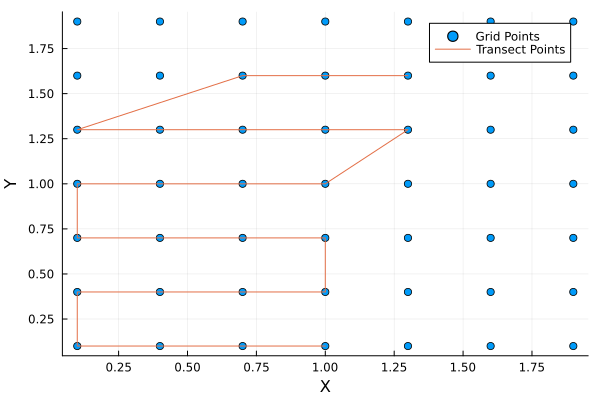

In [91]:
transect_xs = 0.1:0.3:2;
transect_ys = 0.1:0.3:2;
# transect_xs = 0.1:0.1:0.5;
# transect_ys = 0.1:0.3:2;
pts = vec([[x, y] for x in transect_xs, y in transect_ys]);
transect_pts = Transects.create_points(pts);
scatter([p[1] for p in pts], [p[2] for p in pts], label="Grid Points", xlabel="X", ylabel="Y")
plot!([p[1] for p in transect_pts], [p[2] for p in transect_pts], label="Transect Points")

## Controller Setup

In [92]:
# Create STGPKF Problem
problem = STGPKFProblem(grid_pts, ks, kt, dt_min)
kern = ks
ngp_grid_x = synthetic_data.xs
ngp_grid_y = synthetic_data.ys
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

# ASV Start Location
x0s = [@SVector[0.75, 0.75] for i=1:1]

1-element Vector{SVector{2, Float64}}:
 [0.75, 0.75]

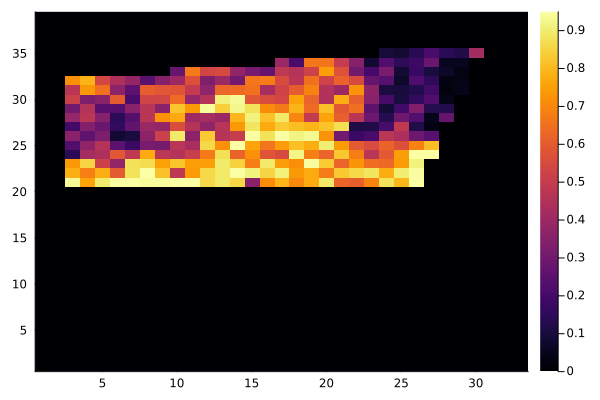

In [93]:
target_q = 0.95

# Set the rated value matrix    
Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
w_rated = ones(Nx, Ny)
w_rated *= w_rated_val

#   Compute the target matrix 
lambda_param = 0.25
delta = -lambda_param*((synthetic_data.data[:,:,1] - w_rated).^2)
q_target_temp = target_q*(exp.(delta)) 


# Mask the matrix such that q_target is zero outisde the domain
# x_domain = range(0, 1.4, length=Nx)
# y_domain = range(0, 6.5, length=Ny)
x_domain = synthetic_data.xs
y_domain = synthetic_data.ys

for i in 1:length(x_domain)
    for j in 1:length(y_domain)
        p = [x_domain[i], y_domain[j]]
        if (p ∈ JordanLakeDomain.convex_polygon.polygon) == false
            q_target_temp[i, j] = 0.0
        end
        if y_domain[j] < 1.0
            q_target_temp[i, j] = 0.0
        end
    end
end


heatmap(q_target_temp')

In [94]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(Δt)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [95]:
function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end

Clarity_delta_new (generic function with 1 method)

In [96]:
function ergo_controller_weighted_2(t, xs, Mean, w_rated_val, convex_polygon;
    ergo_grid,
    ergo_q_map,
    traj,
    umax= 0.15, #30.0 * 60 / 1000,
    ΔT,
    kwargs...
    )
    
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val

    #   Compute the target matrix 
    lambda_param = 0.25
    delta = -lambda_param*((synthetic_data.data[:,:,1] - w_rated).^2)
    q_target_temp = target_q*(exp.(delta)) 


    # Mask the matrix such that q_target is zero outisde the domain
    # x_domain = range(0, 1.4, length=Nx)
    # y_domain = range(0, 6.5, length=Ny)
    x_domain = synthetic_data.xs
    y_domain = synthetic_data.ys

    for i in 1:length(x_domain)
        for j in 1:length(y_domain)
            p = [x_domain[i], y_domain[j]]
            if (p ∈ convex_polygon.polygon) == false
                q_target_temp[i, j] = 0.0
            end
            if y_domain[j] < 1.0
                q_target_temp[i, j] = 0.0
            end
        end
    end
    
    # Get it in the right shape
    q_target_itp = linear_interpolation((x_domain, y_domain), q_target_temp, extrapolation_bc=Interpolations.Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     


    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      

    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
    #             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator_cvx_bound(ergo_grid, x, traj, target_spatial_dist, convex_polygon; umax=umax, do_boundary_correction=true) for x in xs]

    #     println(u)

    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

function heading_calculator(speed, position, waypoint)
    # Calculate the heading to the waypoint
    dx = waypoint[1] - position[1]
    dy = waypoint[2] - position[2]
    heading = atan(dy, dx)
    speed_x = speed * cos(heading)
    speed_y = speed * sin(heading)
    return [speed_x, speed_y]
end

function ergo_controller_waypoints(t, xs, Mean, w_rated_val, convex_polygon;
    ergo_grid,
    ergo_q_map,
    traj,
    transect_pts,
    waypoint_idx,
    umax=0.15, #30.0 * 60 / 1000,
    ΔT,
    kwargs...
    )

    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val

    #   Compute the target matrix 
    lambda_param = 0.25
    delta = -lambda_param*((synthetic_data.data[:,:,1] - w_rated).^2)
    q_target_temp = target_q*(exp.(delta)) 


    # Mask the matrix such that q_target is zero outisde the domain
    # x_domain = range(0, 1.4, length=Nx)
    # y_domain = range(0, 6.5, length=Ny)
    x_domain = synthetic_data.xs
    y_domain = synthetic_data.ys

     for i in 1:length(x_domain)
        for j in 1:length(y_domain)
            p = [x_domain[i], y_domain[j]]
            if (p ∈ convex_polygon.polygon) == false
                q_target_temp[i, j] = 0.0
            end
            if y_domain[j] < 1.0
                q_target_temp[i, j] = 0.0
            end
        end
    end


    # Get it in the right shape
    q_target_itp = linear_interpolation((x_domain, y_domain), q_target_temp, extrapolation_bc=Interpolations.Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      

    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end

    # Get the current waypoint
    current_waypoint = transect_pts[waypoint_idx]

    # Compute the control input to move towards the current waypoint
    u = [heading_calculator(umax, x, current_waypoint) for x in xs]


    u = [@SVector [ux, uy] for (ux, uy) in u]

    # Check if the vehicle has reached the current waypoint
    if norm(xs[1] - current_waypoint) < 0.1
        waypoint_idx += 1
        if waypoint_idx > length(transect_pts)
            waypoint_idx = 1
        end
    end

    return u, q_target_temp, waypoint_idx
end

ergo_controllers_waypoints = [ergo_controller_waypoints for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_waypoints)}:
 ergo_controller_waypoints (generic function with 1 method)

## Generate SOC Target Profile

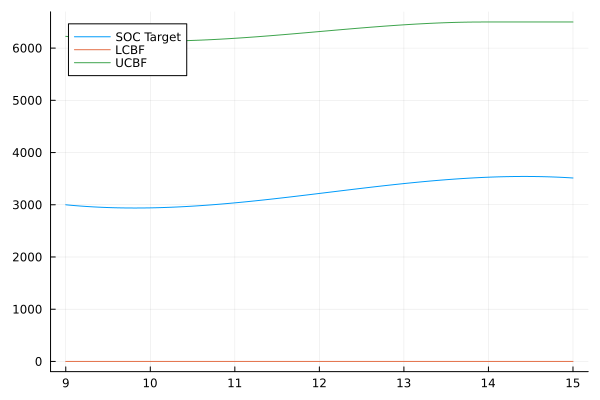

In [97]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts_hrs, dt_hrs);
ucbf = SoCController.compute_ucbf(ts_hrs, dt_hrs);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts_hrs, dt_hrs);
plot(ts_hrs, soc_target, label="SOC Target")
plot!(ts_hrs, lcbf, label="LCBF")
plot!(ts_hrs,ucbf, label="UCBF")

## Simulate

In [98]:
fuse_measurements_every_ΔT = 5.0/(60) # hours
recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
σ_t = zeros(length(xs), length(ys));

@time res_ergo_hp =  SimulatorST.simulate_known_transect(ts_min, x0s, soc_begin, ergo_controller_waypoints, soc_target, w_rated_val, JordanLakeDomain.convex_polygon, problem; 
    ngpkf_grid=ngpkf_grid, 
    EnvData=synthetic_data,
    transect_pts=transect_pts, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:25:08
Progress:   1%|▍                                        |  ETA: 0:24:47
Progress:   2%|▋                                        |  ETA: 0:23:59
Progress:   2%|▉                                        |  ETA: 0:23:44
Progress:   3%|█                                        |  ETA: 0:23:53
Progress:   3%|█▎                                       |  ETA: 0:23:50
Progress:   4%|█▌                                       |  ETA: 0:23:16
Progress:   4%|█▋                                       |  ETA: 0:23:19
Progress:   5%|█▉                                       |  ETA: 0:23:23
Progress:   5%|██▏                                      |  ETA: 0:22:55
Progress:   6%|██▎                                      |  ETA: 0:22:54
Progress:   6%|██▌                                      |  ETA: 0:22:51
Progress:   7%|██▊                                      |  ETA: 0:22

1475.134459 seconds (141.82 M allocations: 434.995 GiB, 10.52% gc time, 0.07% compilation time: 78% of which was recompilation)


Main.SimulatorST.SimResultWeightedSpeed{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Matrix{Float64}}, Vector{Matrix{Float64}}}(540.0:0.041666666666666664:900.0, Vector{SVector{2, Float64}}[[[0.75, 0.75]], [[0.7500012504145567, 0.7499967489221525]], [[0.7500045534939243, 0.7499881609157969]], [[0.7500092463986437, 0.7499759593635262]], [[0.7500153972335738, 0.7499599671927082]], [[0.7500230199749177, 0.7499401480652141]], [[0.7500321285979413, 0.7499164656453527]], [[0.7500427370767598, 0.7498888836004245]], [[0.7500548593841135, 0.7498573656013048]], [[0.7500685094911306, 0.7498218753230605]]  …  [[1.2121507575349435, 1.2332401860583997]], [[1.213305333044424, 1.234117589710743]], [[1.2144599067808246, 1.234994992015659]], [[1.215614478744392, 1.2358723929733353]], [[1.2167690489353733, 1.23674

In [99]:
jldsave("20250630_transect_6hr_fixed2.jld2"; res_ergo_hp, synthetic_data, soc_target, ts_hrs, w_rated_val)